# CAMP2Ex RF17 insitu

This notebook tries to summarize "what the clouds looked like" from an insitu perspective.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx
plt.style.use('seaborn-v0_8-talk')

In [3]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:110: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)


In [4]:
start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')
# start_time = pd.to_datetime('2019-10-02 01:45:25')
# end_time = pd.to_datetime('2019-10-02 01:46:10')

p3_subset = p3[
    # (p3['N_L'] > 10000)
    (p3['ext_km'] > 0.3)
    & (p3.index > start_time)
    & (p3.index < end_time)
    & (p3['GPS_Altitude'] < 1250)
]

In [5]:
N, bins = cx.combine_PSD(
    p3_subset[cx.FCDP_BIN_NAMES].to_numpy(),
    cx.FCDP_BINS,
    p3_subset[cx.TDS_BIN_NAMES].to_numpy(),
    cx.TDS_BINS,
    40
)

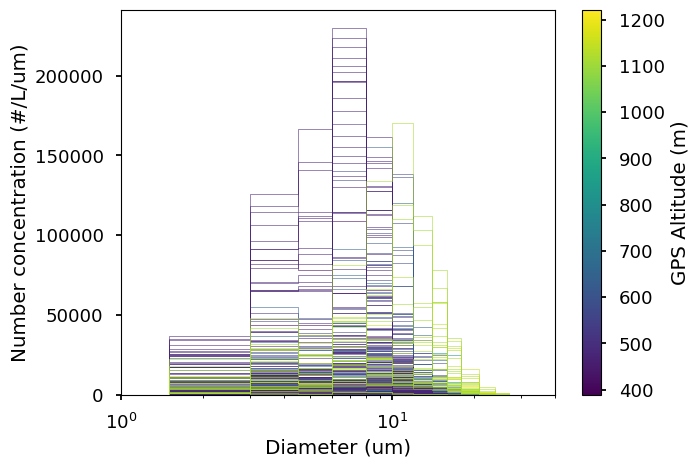

In [6]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors

f, ax = plt.subplots(1, 1, figsize=(7,5))
altitudes = [p3_subset.iloc[i]['GPS_Altitude'] for i in range(N.shape[0])]
norm = mcolors.Normalize(vmin=min(altitudes), vmax=max(altitudes))
cmap = cm.viridis

for i in range(N.shape[0]):
    color = cmap(norm(altitudes[i]))
    ax.stairs(N[i,:], bins, color=color, label=f'{altitudes[i]:.0f} m')

ax.set_xscale('log')
ax.set_xlabel('Diameter (um)')
ax.set_ylabel('Number concentration (#/L/um)')
ax.set_xlim([10**0, 4*10**1])

# Optional: add a colorbar
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('GPS Altitude (m)')

<Axes: ylabel='Frequency'>

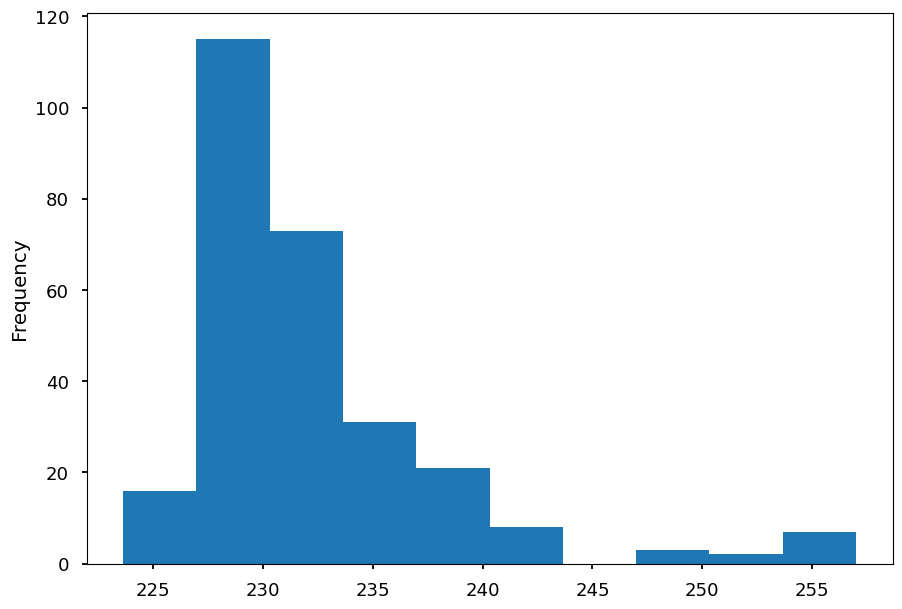

In [7]:
p3_subset['Length_m'].plot.hist()

Re = 3.938 [um/km] * z + 2.895 [um]


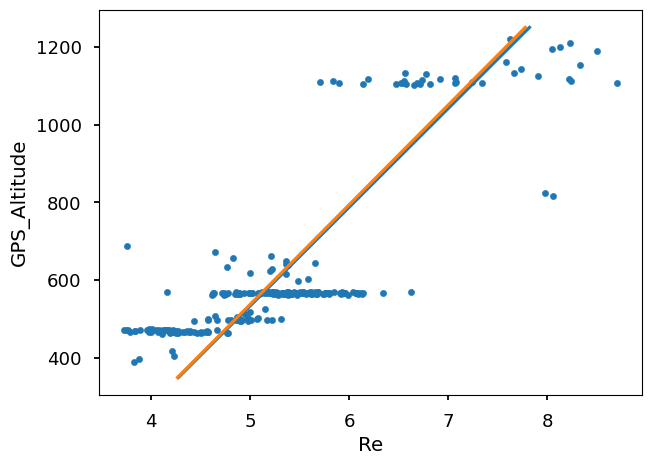

In [8]:
slope, intercept = cx.VertLinearRegression(p3_subset, x_var='GPS_Altitude', y_var='Re')
f, ax = plt.subplots(1, 1, figsize=(7,5))
p3_subset.plot.scatter(x='Re', y='GPS_Altitude', ax=ax)
x = np.array([350, 1250])
y = slope * x + intercept
ax.plot(y, x)
ax.plot(3.9*1e-3*x+2.9, x)
print(f'Re = {slope*1e3:.3f} [um/km] * z + {intercept:.3f} [um]')

np.float64(20.25849924639662)

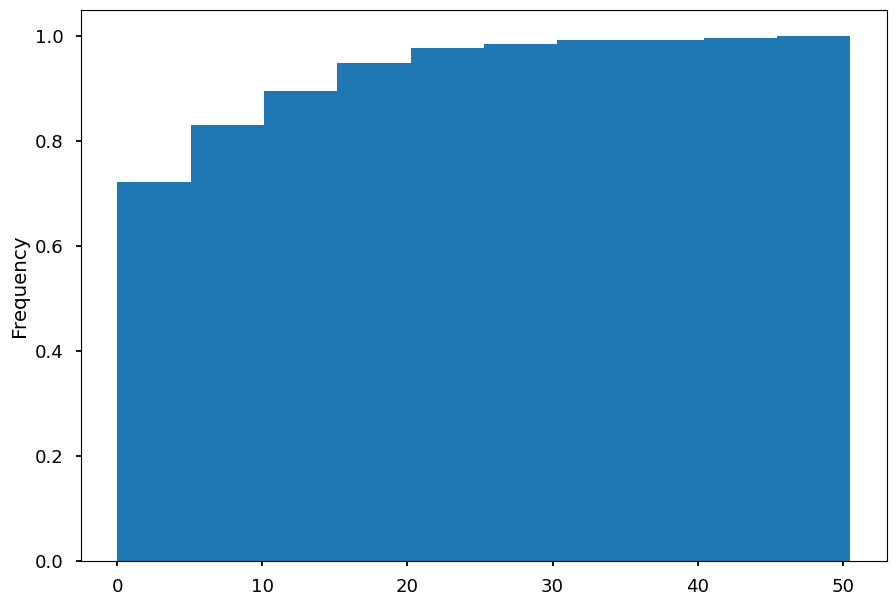

In [9]:
p3_subset['pct_ALWC'].plot.hist(cumulative=True, density=True)
np.percentile(p3_subset['pct_ALWC'], 95)

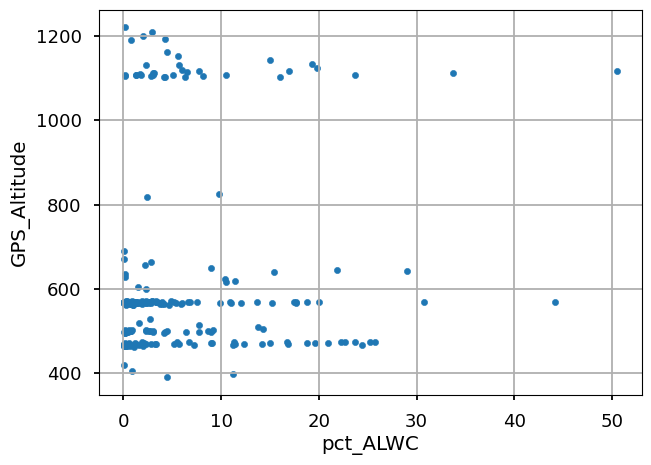

In [10]:
f, ax = plt.subplots(1, 1, figsize=(7, 5))
p3_subset.plot.scatter(x='pct_ALWC', y='GPS_Altitude', c='tab:blue', ax=ax)
ax.grid()

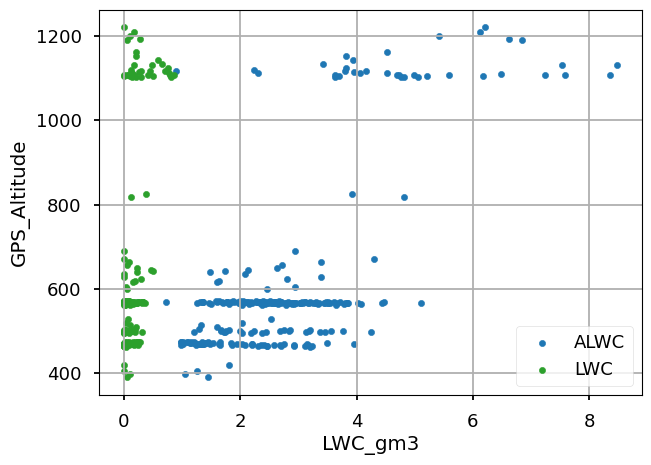

In [11]:
f, ax = plt.subplots(1, 1, figsize=(7, 5))
p3_subset.plot.scatter(x='ALWC_gm3', y='GPS_Altitude', c='tab:blue', ax=ax, label='ALWC')
p3_subset.plot.scatter(x='LWC_gm3', y='GPS_Altitude', c='tab:green', ax=ax, label='LWC')
ax.grid()

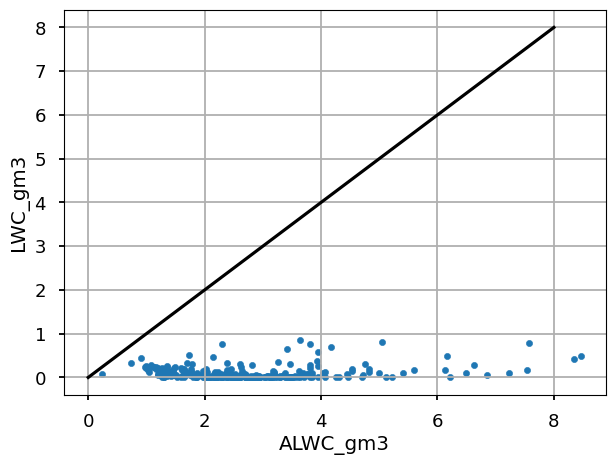

In [12]:
f, ax = plt.subplots(1, 1, figsize=(7, 5))
p3_subset.plot.scatter(x='ALWC_gm3', y='LWC_gm3', ax=ax)
ax.plot([0, 8], [0, 8], 'k')
ax.grid()

<Axes: xlabel='datetime'>

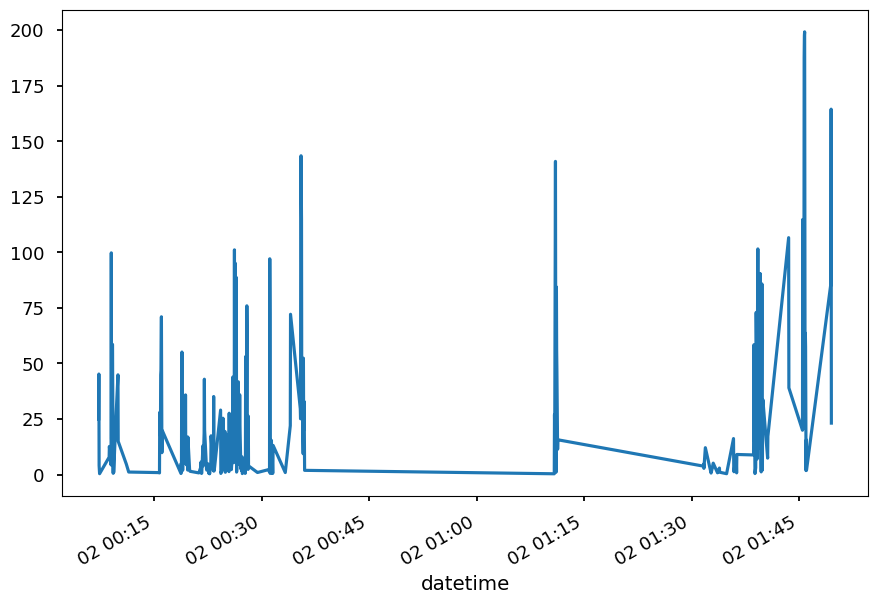

In [13]:
p3_subset['ext_km'].plot()

<Axes: xlabel='ext_km', ylabel='GPS_Altitude'>

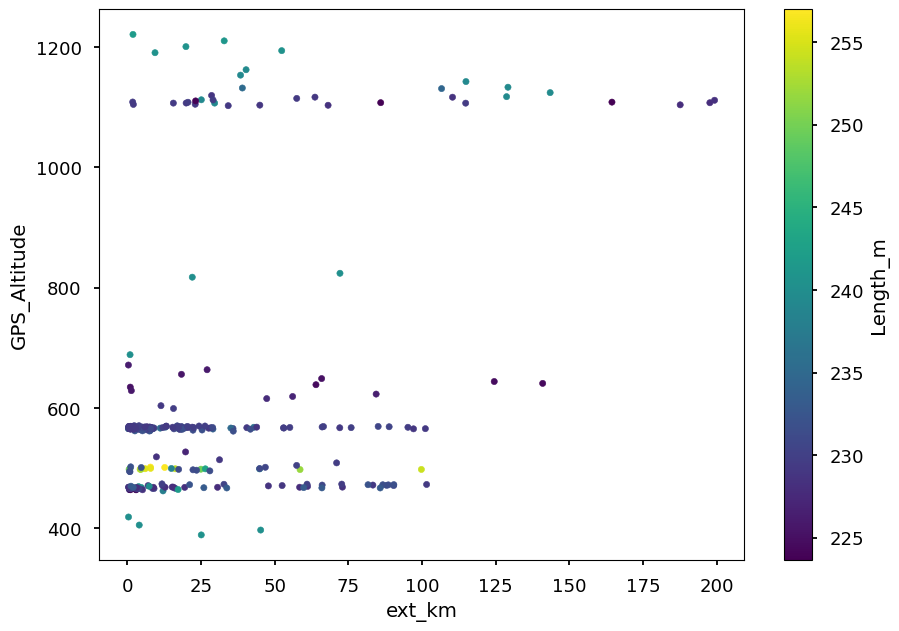

In [14]:
p3_subset.plot.scatter(x='ext_km', y='GPS_Altitude', c='Length_m')

Text(0.5, 0, 'Extinction (km$^{-1}$)')

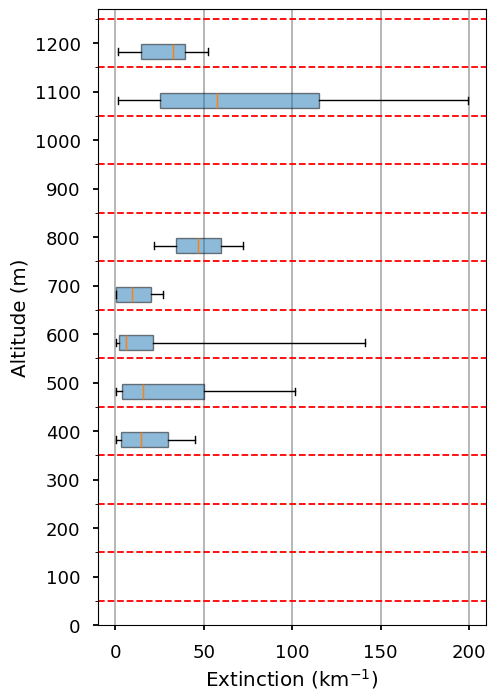

In [15]:
positions = np.arange(400, 1201, 100)
p3_ext_box = []
for z in positions:
    tmp = p3_subset.loc[
        (p3_subset['GPS_Altitude'] > z-50)
        & (p3_subset['GPS_Altitude'] <= z+50)
    ]['ext_km'].to_numpy()
    p3_ext_box.append(tmp)

box_kwargs = {
    'vert':False,
    'manage_ticks':False,
    'patch_artist':True,
    'widths':30,
    'whis':(0,100)
}

f, ax = plt.subplots(1, 1, figsize=(5, 8))
p3_bplot = ax.boxplot(p3_ext_box, positions=np.array(positions)-18, **box_kwargs)
for patch in p3_bplot['boxes']:
    patch.set_facecolor('tab:blue')
    patch.set_alpha(0.5)

ax.set_xlabel('Extinction (1/km)')
ax.set_ylabel('Altitude (m)')
ax.grid(visible=True, which='major', axis='x')
ax.grid(visible=True, which='minor', axis='y', color='r', linestyle='--')

ax.set_yticks(np.arange(0, 1400, 100))
ax.set_yticks(np.arange(50, 1300, 100), minor=True)
# ax.set_xlim([-10, 110])
ax.set_ylim([0, 1270])
ax.set_xlabel(r'Extinction (km$^{-1}$)')
